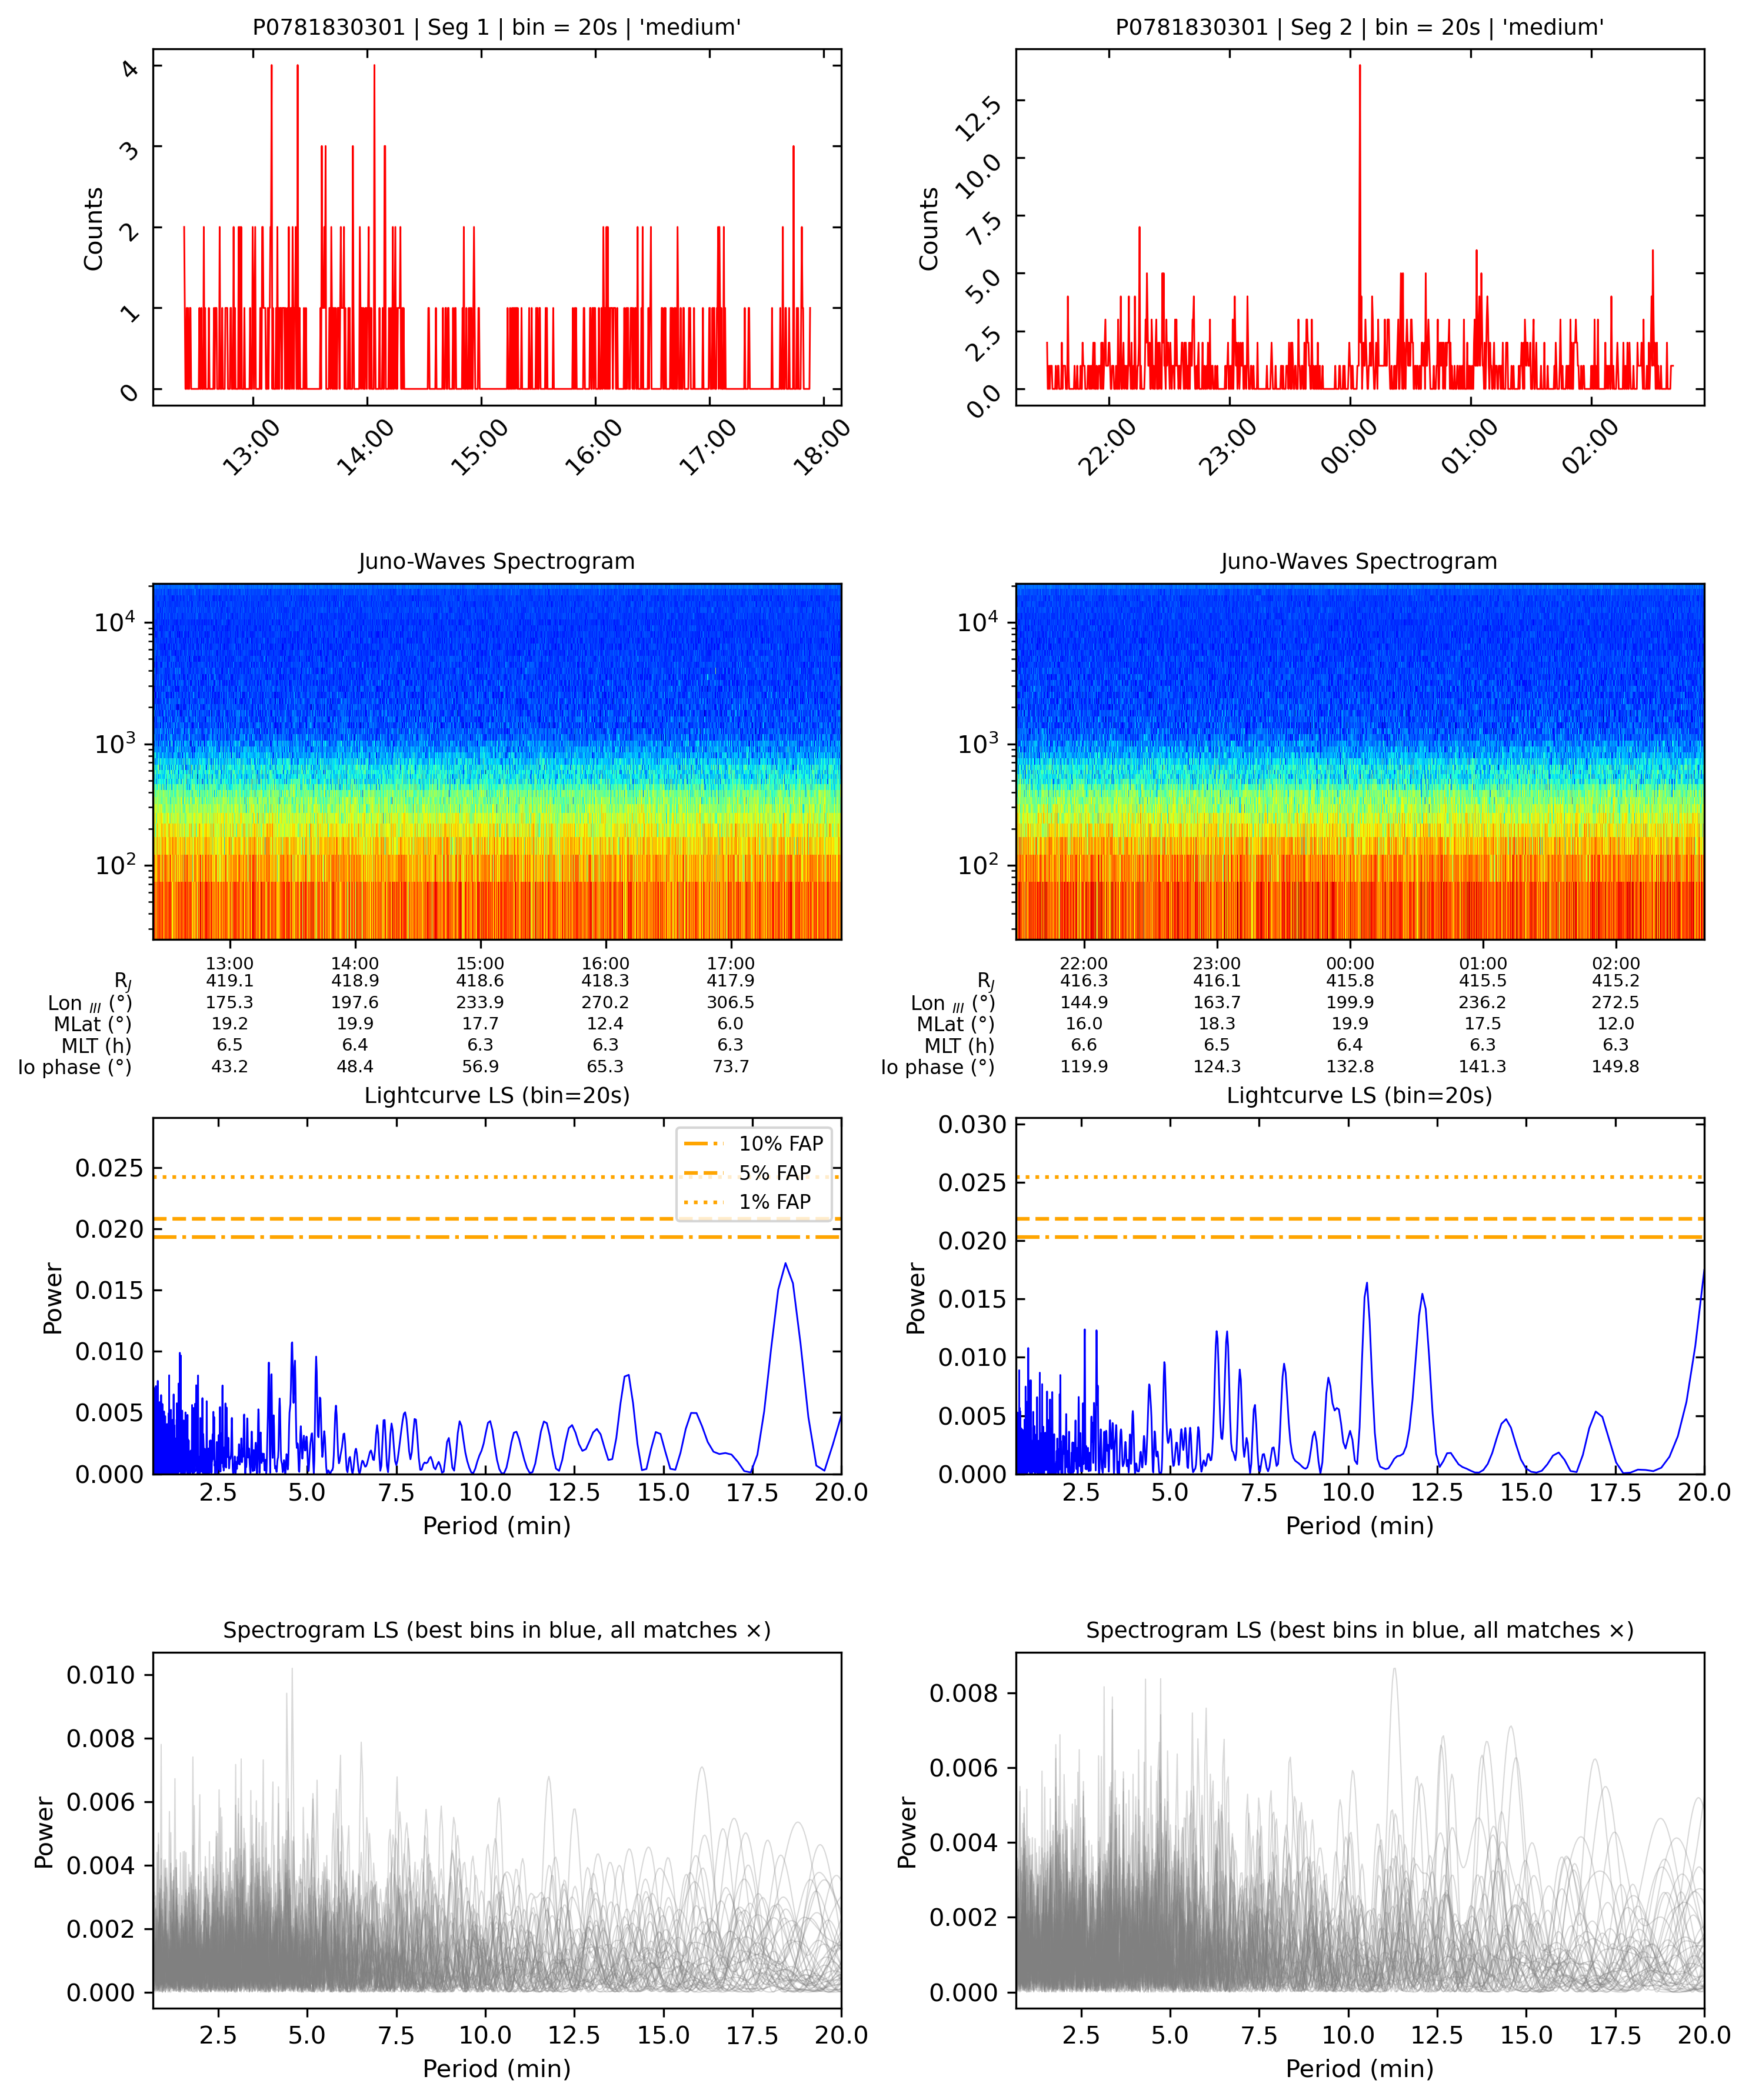

Finished processing P0781830301


KeyboardInterrupt: 

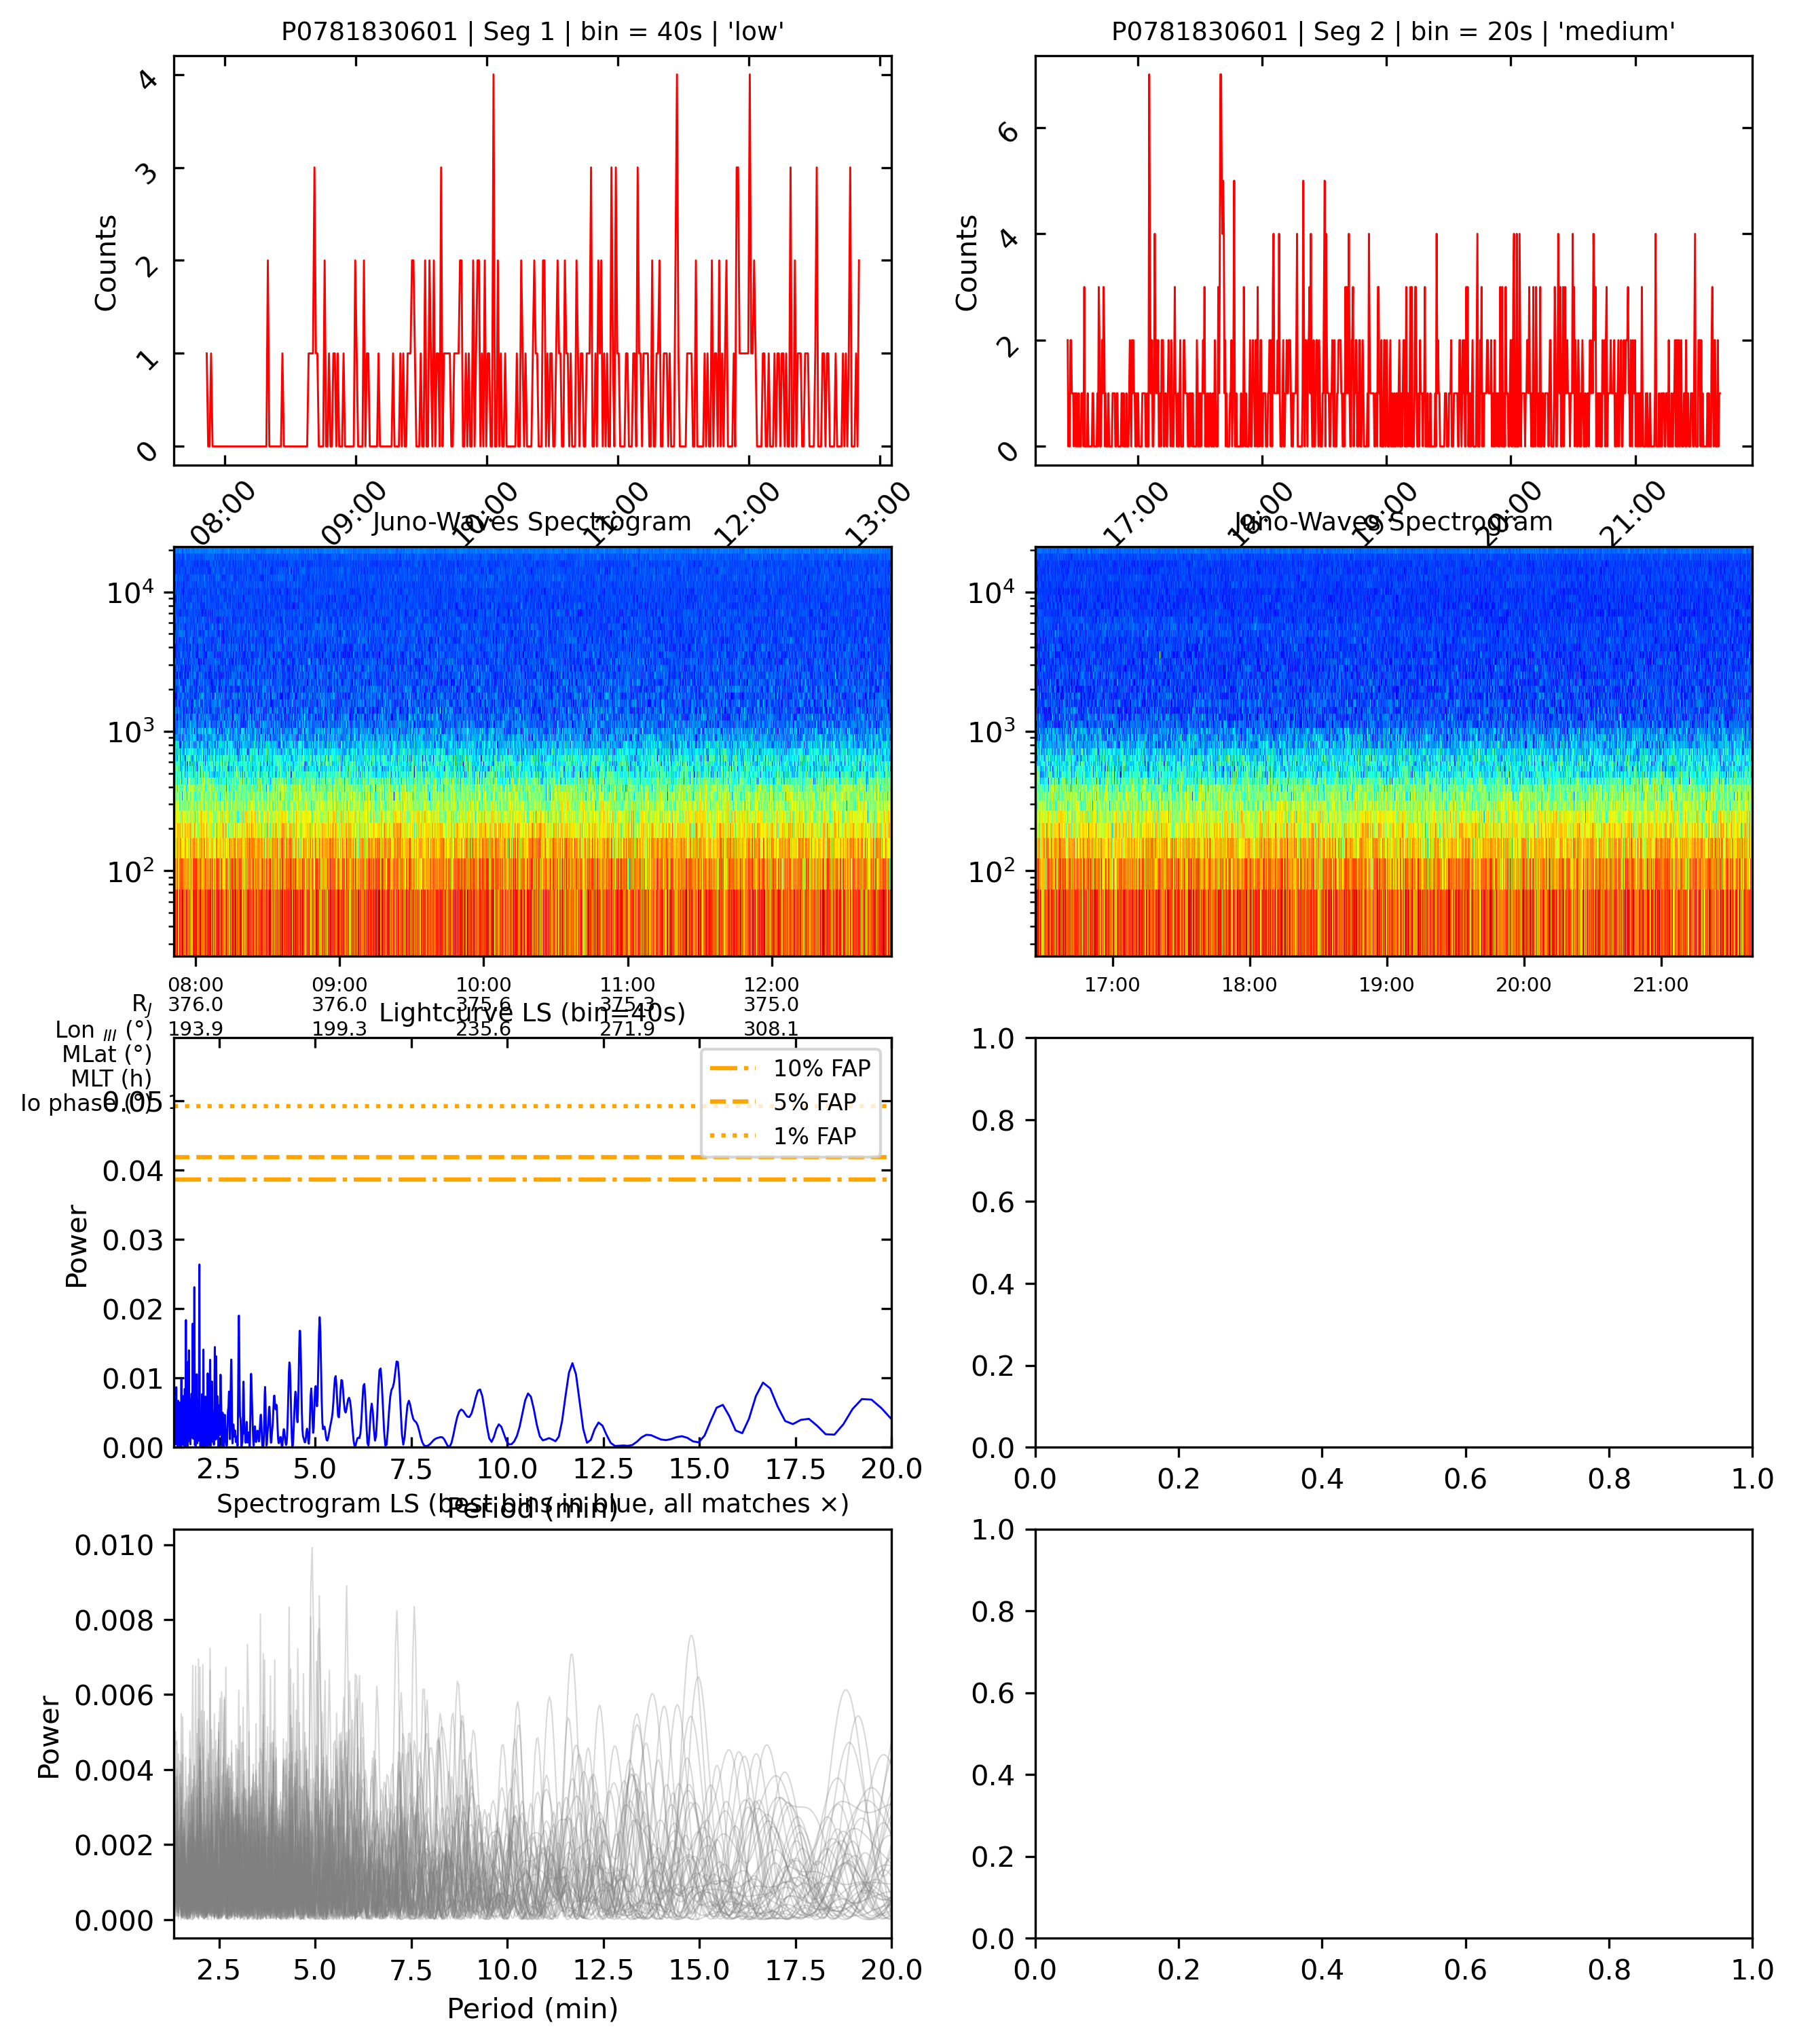

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import matplotlib.dates as mdates

from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

from matplotlib.dates import DateFormatter, HourLocator, MinuteLocator
from matplotlib.colors import LogNorm

from scipy.signal import find_peaks

import das2
import warnings
warnings.filterwarnings("ignore")

# ─── GLOBAL SETTINGS ───────────────────────────────────────────────────────────────────────
tick_interval_h = 1      # major tick every 1 hour
minor_interval_h = 1     # minor tick every 1 hour (if desired)

ident = ['P0781830301', 'P0781830601', 'P0801930701', 'P0801930801', 'P0801930901',
         'P0801931901', 'P0842810501', 'P0842811001', 'P0842811501', 'P0842812001',
         'P0861950201', 'P0882110501', 'P0882110601']


base_bin_size = 10       # seconds; used only to categorise first
data_dir      = 'Data_Files/Fenn_Data/'

# ─── UTILITY FUNCTIONS ─────────────────────────────────────────────────────────────────────
def get_das2_data(start_time, end_time):
    """
    Fetch DAS2 spectrogram for [start_time, end_time] (strings in ISO); return (vX, vY, vZ).
    """
    st = Time(start_time).datetime.strftime('%Y-%m-%dT%H:%M')
    et = Time(end_time).datetime.strftime('%Y-%m-%dT%H:%M')
    src = das2.get_source('site:/uiowa/juno/wav/survey/das2')
    ds  = src.get({'time': (st, et, 4.0)})[0]
    return ds['Time']['center'], ds['frequency']['center'], ds['spec_dens']['center']


def load_combined_times(obs_id, data_dir):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return two arrays:
      • times_datetime: numpy array of Python datetimes
      • times_cxcsec:   numpy array of CXC seconds (float)
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt = []
    list_cxc = []

    for file in files:
        data = Table.read(file, format="fits")
        
        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)  # approximate XMM as Earth-based

        distance     = (jup - xmm).norm()                   # in AU
        light_time_s = (distance.to('m') / c).to('s').value  # in seconds
        
        corrected_t = t - light_time_s * u.s

        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec, threshold=3600):
    """
    Identify indices where the gap between consecutive times > threshold seconds.
    Returns (list_of_(gap_start, gap_end), array_of_gap_indices).
    """
    dt      = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps    = [(times_cxcsec[i], times_cxcsec[i+1]) for i in indices]
    return gaps, indices


def bin_photon_times(photon_times, bin_size):
    """
    Bin photon_times (given in CXC seconds) into bins of width=bin_size (seconds).
    Returns (bin_centers, counts).
    """
    start = photon_times.min()
    end   = photon_times.max()
    bins  = np.arange(start, end + bin_size, bin_size)
    counts, bin_edges = np.histogram(photon_times, bins=bins)
    centers = bin_edges[:-1] + (bin_size / 2)
    return centers, counts


def categorize_segment(counts, low_thresh=300, high_thresh=1000):
    """
    Given a 1D counts array, sum it and decide:
      total < low_thresh   → 'low'
      low_thresh ≤ total < high_thresh → 'medium'
      total ≥ high_thresh  → 'high'
    """
    total = np.sum(counts)
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    else:
        return 'high'


def dynamic_bin_size(category, base_bin=20):
    """
    Return an integer bin-size (in seconds) depending on category:
      'low'    →  base_bin × 4
      'medium' →  base_bin × 2
      'high'   →  base_bin
    """
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    else:
        return base_bin


# ─── LIGHTCURVE‐RELATED FUNCTIONS ───────────────────────────────────────────────────────────

def prepare_segment_bins(raw_segment, base_bin):
    """
    1) Do an initial bin with base_bin solely to categorise the segment.
    2) Call categorize_segment(...) on that binned counts.
    3) Compute seg_bin = dynamic_bin_size(category, base_bin).
    4) Re‐bin raw_segment with seg_bin; return (seg_bin, hist_centers, hist_counts, category).
    """
    # 1) initial bin
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category   = categorize_segment(counts0)

    # 2) get final bin size for this segment
    seg_bin = dynamic_bin_size(category, base_bin)

    # 3) re‐bin with seg_bin
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category


def compute_lightcurve_ls(hist_centers, hist_counts, seg_bin):
    """
    Compute LS periodogram for a lightcurve binned at seg_bin s, *only* between
    periods [2 × seg_bin, 20 minutes]. Returns:
      (period_lc, power_lc, fap10, fap05, fap01)
    where period_lc is in minutes, and fapX are power‐threshold scalars.
    """
    # Define period limits in seconds
    shortest_period = 2 * seg_bin        # seconds
    longest_period  = 20 * 60            # 1200 seconds

    # Convert to frequency limits
    freq_max = 1.0 / shortest_period     # highest frequency (Hz)
    freq_min = 1.0 / longest_period      # lowest frequency  (Hz)

    ls_lc = LombScargle(hist_centers, hist_counts)
    freq_lc, power_lc = ls_lc.autopower(
        minimum_frequency = freq_min,
        maximum_frequency = freq_max
    )

    # Convert to period (minutes) for plotting
    period_lc = 1.0 / freq_lc / 60.0

    # Compute FAP levels over exactly this [freq_min, freq_max] band
    fap10 = ls_lc.false_alarm_level(0.10,
                                    minimum_frequency = freq_min,
                                    maximum_frequency = freq_max)
    fap05 = ls_lc.false_alarm_level(0.05,
                                    minimum_frequency = freq_min,
                                    maximum_frequency = freq_max)
    fap01 = ls_lc.false_alarm_level(0.01,
                                    minimum_frequency = freq_min,
                                    maximum_frequency = freq_max)

    return period_lc, power_lc, fap10, fap05, fap01


def plot_lightcurve_subplot(ax, hist_centers, hist_counts, seg_bin, category, obs_id, seg_index):
    """
    Plot row 0: the binned lightcurve itself, labelled with seg_bin and category.
    """
    hist_dt = Time(hist_centers, format='cxcsec').datetime
    ax.plot(hist_dt, hist_counts, c='red', lw=0.7)

    title = f"{obs_id} | Seg {seg_index+1} | bin = {seg_bin}s | {category!r}"
    ax.set_title(title, fontsize=9)

    ax.xaxis.set_major_locator(HourLocator(interval=1))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(rotation=45, direction='in', top=True, right=True)
    ax.set_ylabel("Counts")


def plot_lc_ls_subplot(ax, period_lc, power_lc, fap10, fap05, fap01, seg_bin):
    """
    Plot the LC Lomb–Scargle periodogram (row 2), draw FAP lines,
    and mark local maxima above the 5% FAP with a red “×” by manual detection.
    """
    # 1) Plot the periodogram curve
    ax.plot(period_lc, power_lc, lw=0.7, c='blue')
    ax.set_xlim(2 * seg_bin / 60.0, 20.0)  # in minutes

    # 2) Draw horizontal FAP lines
    ax.axhline(fap10, linestyle='-.', color='orange', label='10% FAP')
    ax.axhline(fap05, linestyle='--', color='orange', label='5% FAP')
    ax.axhline(fap01, linestyle=':',  color='orange', label='1% FAP')

    # 3) Manually find local maxima above fap05
    peaks = []
    for i in range(1, len(power_lc) - 1):
        if (
            (power_lc[i] > fap05) and
            (power_lc[i] > power_lc[i - 1]) and
            (power_lc[i] > power_lc[i + 1])
        ):
            peaks.append(i)

    peaks = np.array(peaks, dtype=int)

    # 4) Overplot red “×” at those (period, power) coordinates
    if peaks.size > 0:
        ax.scatter(
            period_lc[peaks],
            power_lc[peaks],
            marker='x',
            color='red',
            s=50,
            label='Local maxima > 5% FAP'
        )

    # 5) Final formatting
    ax.set_title(f"Lightcurve LS (bin={seg_bin}s)", fontsize=9)
    ax.set_xlabel("Period (min)")
    ax.set_ylabel("Power")
    ax.tick_params(direction='in', top=True, right=True)
    ax.set_ylim(0, 1.2 * fap01)

    ax.legend(fontsize=8, loc='upper right')


# ─── SPECTROGRAM‐RELATED FUNCTIONS ─────────────────────────────────────────────────────────

def plot_spectrogram_subplot(ax, start_iso, end_iso):
    """
    Plot row 1: DAS2 spectrogram for time span [start_iso, end_iso], then overlay ephemeris rows.
    Returns (vX, vY, vZ, t_flat, dt_sec).
    """
    # 1) Fetch from DAS2
    vX, vY, vZ = get_das2_data(start_iso, end_iso)
    t_spec = vX.array
    f_spec = vY.array
    S_spec = vZ.array

    # Flatten time
    if t_spec.ndim == 2:
        t_flat = t_spec[:, 0]
    else:
        t_flat = t_spec

    ax.set_xlim(t_flat[0], t_flat[-1])
    if np.issubdtype(t_flat.dtype, np.datetime64):
        dt_sec = int((t_flat[1] - t_flat[0]) / np.timedelta64(1, 's'))
    else:
        dt_sec = float(t_flat[1] - t_flat[0])

    # Tick formatting
    ax.xaxis.set_major_locator(HourLocator(interval=tick_interval_h))
    ax.xaxis.set_minor_locator(HourLocator(interval=minor_interval_h))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(axis='x', which='minor', length=4)
    ax.tick_params(axis='x', which='major', labelsize=7)

    # Plot spectrogram (log-norm)
    pcm = ax.pcolormesh(
        t_spec, f_spec, S_spec,
        norm=LogNorm(S_spec.min(), S_spec.max()),
        cmap='jet'
    )
    ax.set_yscale('log')
    ax.set_title("Juno-Waves Spectrogram", fontsize=9)

    # 2) Overlay ephemeris (if available)
    try:
        eph_src = das2.get_source(
            'tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2'
        )
        ds_eph = eph_src.get({'time': (start_iso, end_iso, dt_sec)})[0]

        rad   = ds_eph['radius']['center'].array
        lon3  = ds_eph['long']['center'].array
        mlatE = ds_eph['mlat']['center'].array
        mltE  = ds_eph['mlt']['center'].array
        ioE   = ds_eph['io_phase']['center'].array

        if mltE.dtype.kind == 'm':
            mltE = (mltE / np.timedelta64(1, 'h')).astype(float)

        # Major‐tick times for ephemeris
        t0  = t_flat[0]
        t1  = t_flat[-1]
        t0h = t0.astype('datetime64[h]')
        t1h = t1.astype('datetime64[h]') + np.timedelta64(1, 'h')
        major_ticks_dt = np.arange(
            t0h, t1h, np.timedelta64(tick_interval_h, 'h')
        )
        idx_eph = [np.argmin(np.abs(t_flat - mt)) for mt in major_ticks_dt]

        row_lbls = ["R$_J$", "Lon $_{III}$ (°)", "MLat (°)", "MLT (h)", "Io phase (°)"]
        row_vals = [
            rad[idx_eph],
            lon3[idx_eph],
            mlatE[idx_eph],
            mltE[idx_eph],
            ioE[idx_eph]
        ]

        row_spacing = 0.06
        for j, (label, vals) in enumerate(zip(row_lbls, row_vals)):
            off = -row_spacing * (j + 1.2)
            sax = ax.secondary_xaxis(
                off,
                functions=(lambda x: x, lambda x: x)
            )
            sax.xaxis.set_major_locator(HourLocator(interval=tick_interval_h))
            lbls = []
            for v in vals:
                try:
                    lbls.append(f"{float(v):.1f}")
                except:
                    lbls.append(str(v))
            sax.set_xticklabels(lbls, rotation=0, va='top', fontsize=7)
            sax.spines['bottom'].set_visible(False)
            sax.tick_params(axis='x', length=0)
            ax.text(
                -0.03, off - 0.05,
                label,
                transform=ax.transAxes,
                ha='right', va='center',
                fontsize=8
            )
    except Exception:
        ax.text(
            0.5, 0.5, "No Ephemeris data",
            transform=ax.transAxes, ha='center', va='center'
        )

    return vX, vY, vZ, t_flat, dt_sec


def identify_best_channels(vX, vY, vZ, lc_peak_periods, seg_bin):
    """
    For each LC peak P_lc, find the single channel j* whose local maximum
    closest to P_lc sits highest above its own 5% FAP. Return set of all such j*.
    """
    # Flatten vX into 1D time array in seconds
    tx = vX.array
    if tx.ndim == 2:
        t1d = tx[:, 0]
    else:
        t1d = tx

    if np.issubdtype(t1d.dtype, np.datetime64):
        times_sec = (t1d - t1d[0]).astype('timedelta64[s]').astype(float)
    else:
        times_sec = t1d

    # Extract 1D frequency array from vY
    fy = vY.array
    if fy.ndim == 2:
        f1d = fy[0, :]
    else:
        f1d = fy

    # Build common period grid [2×seg_bin … 20 min], convert to minutes
    min_p = 2 * seg_bin
    max_p = 20 * 60
    n_p   = 500
    periods_sec = np.linspace(min_p, max_p, n_p)
    freqs       = 1.0 / periods_sec
    periods_min = periods_sec / 60.0

    # Frequency range for FAP
    fap_min = 1.0 / max_p
    fap_max = 1.0 / min_p

    num_chans = vZ.array.shape[1]
    fap05_list = np.full(num_chans, np.nan)
    local_max_list = [None]*num_chans
    pw_list = [None]*num_chans

    # Pre‐compute each channel’s LS, power spectrum, FAP, and local maxima
    for j in range(num_chans):
        y = vZ.array[:, j]
        if not np.any(np.isfinite(y)):
            continue

        ls_sp = LombScargle(times_sec, y)
        pw    = ls_sp.power(freqs)
        pw_list[j] = pw

        # 5% FAP
        channel_fap05 = ls_sp.false_alarm_level(
            0.05,
            minimum_frequency = fap_min,
            maximum_frequency = fap_max
        )
        fap05_list[j] = channel_fap05

        # local maxima indices
        lm_idx = []
        for k in range(1, len(pw) - 1):
            if pw[k] > pw[k-1] and pw[k] > pw[k+1]:
                lm_idx.append(k)
        local_max_list[j] = np.array(lm_idx, dtype=int)

    tol = 0.5  # minutes tolerance
    best_channels = set()

    # For each LC peak, find the channel with maximum excess
    for P_lc in lc_peak_periods:
        best_excess_for_P = -np.inf
        best_j_for_P = None

        for j in range(num_chans):
            pw = pw_list[j]
            if pw is None:
                continue

            f05    = fap05_list[j]
            lm_idx = local_max_list[j]
            if lm_idx.size == 0:
                continue

            valid_k = []
            for k in lm_idx:
                if pw[k] <= f05:
                    continue
                if abs(periods_min[k] - P_lc) <= tol:
                    valid_k.append(k)
            if not valid_k:
                continue

            excess_vals = pw[np.array(valid_k)] - f05
            this_excess = np.max(excess_vals)
            if this_excess > best_excess_for_P:
                best_excess_for_P = this_excess
                best_j_for_P = j

        if best_j_for_P is not None:
            best_channels.add(best_j_for_P)

    return best_channels


def plot_spectrogram_ls_subplot(ax, vX, vY, vZ, lc_peak_periods, seg_bin, best_channels):
    """
    Plot LS of each spectrogram channel (row 3). Draw every channel in grey,
    but overplot channels in best_channels in blue (labeled in legend),
    and draw red “×” at every matched peak.
    """
    # Flatten vX into 1D time array in seconds
    tx = vX.array
    if tx.ndim == 2:
        t1d = tx[:, 0]
    else:
        t1d = tx

    if np.issubdtype(t1d.dtype, np.datetime64):
        times_sec = (t1d - t1d[0]).astype('timedelta64[s]').astype(float)
    else:
        times_sec = t1d

    # Extract 1D frequency array from vY
    fy = vY.array
    if fy.ndim == 2:
        f1d = fy[0, :]
    else:
        f1d = fy

    # Build common period grid: [2×seg_bin … 20 min], convert to minutes
    min_p = 2 * seg_bin
    max_p = 20 * 60
    n_p   = 500
    periods_sec = np.linspace(min_p, max_p, n_p)
    freqs       = 1.0 / periods_sec
    periods_min = periods_sec / 60.0

    # Frequency range for FAP
    fap_min = 1.0 / max_p
    fap_max = 1.0 / min_p

    num_chans = vZ.array.shape[1]
    fap05_list = np.full(num_chans, np.nan)
    local_max_list = [None]*num_chans
    pw_list = [None]*num_chans

    # Pre‐compute each channel’s LS, power, FAP, local maxima (again)
    for j in range(num_chans):
        y = vZ.array[:, j]
        if not np.any(np.isfinite(y)):
            continue

        ls_sp = LombScargle(times_sec, y)
        pw    = ls_sp.power(freqs)
        pw_list[j] = pw

        channel_fap05 = ls_sp.false_alarm_level(
            0.05,
            minimum_frequency = fap_min,
            maximum_frequency = fap_max
        )
        fap05_list[j] = channel_fap05

        lm_idx = []
        for k in range(1, len(pw) - 1):
            if pw[k] > pw[k-1] and pw[k] > pw[k+1]:
                lm_idx.append(k)
        local_max_list[j] = np.array(lm_idx, dtype=int)

    tol = 0.5  # minutes tolerance

    # Plot each channel’s LS
    for j in range(num_chans):
        pw = pw_list[j]
        if pw is None:
            continue

        if j in best_channels:
            ax.plot(
                periods_min, pw,
                color='blue', alpha=0.7, lw=0.7,
                label=f"{f1d[j]:.3f} Hz"
            )
        else:
            ax.plot(
                periods_min, pw,
                color='grey', alpha=0.3, lw=0.5
            )

        # Overplot red “×” at every matched peak
        f05    = fap05_list[j]
        lm_idx = local_max_list[j]
        if lm_idx is None or lm_idx.size == 0:
            continue

        for k in lm_idx:
            if pw[k] <= f05:
                continue
            if np.any(np.abs(periods_min[k] - lc_peak_periods) <= tol):
                ax.scatter(
                    periods_min[k], pw[k],
                    marker='x', color='red', s=50
                )

    # Final formatting
    ax.set_xlim(min_p/60.0, max_p/60.0)
    ax.set_xlabel("Period (min)")
    ax.set_ylabel("Power")
    ax.set_title("Spectrogram LS (best bins in blue, all matches ×)", fontsize=9)
    if best_channels:
        ax.legend(fontsize=8, loc='upper right')


# ─── MAIN WRAPPER ─────────────────────────────────────────────────────────────────────────

def plot_segment_analysis(raw_photon_times, gap_indices, obs_id=""):
    """
    Top‐level function that splits raw_photon_times into continuous segments using gap_indices,
    and for each segment calls the helper functions in the 4×N plot grid.
    """
    # 1) Split into continuous segments
    split_pts = np.concatenate(([0], gap_indices + 1, [len(raw_photon_times)]))
    segments = []
    seg_times_iso = []
    for i in range(len(split_pts)-1):
        seg = raw_photon_times[split_pts[i]: split_pts[i+1]]
        if len(seg) > 5:
            segments.append(seg)
            seg_times_iso.append((
                Time(seg[0], format='cxcsec').iso,
                Time(seg[-1], format='cxcsec').iso
            ))

    n = len(segments)
    if n == 0:
        print(f"No valid segments for {obs_id}")
        return

    # 2) Prepare 4×n grid
    fig, axes = plt.subplots(
        4, n,
        figsize=(5*n, 12),
        dpi=300,
        sharex=False,
        gridspec_kw={'height_ratios': [1,1,1,1]}
    )
    if n == 1:
        axes = axes[:, np.newaxis]

    for i, seg in enumerate(segments):
        start_iso, end_iso = seg_times_iso[i]

        # ── bin & category → seg_bin, hist_centers, hist_counts, category ───────────
        seg_bin, hist_centers, hist_counts, category = prepare_segment_bins(seg, base_bin_size)

        # ── Row 0: Lightcurve plot ─────────────────────────────────────────────────
        ax0 = axes[0, i]
        plot_lightcurve_subplot(ax0, hist_centers, hist_counts, seg_bin, category, obs_id, i)

        # ── Row 1: Spectrogram + Ephemeris ────────────────────────────────────────
        ax1 = axes[1, i]
        vX, vY, vZ, t_flat, dt_sec = plot_spectrogram_subplot(ax1, start_iso, end_iso)

        # ── Row 2: LS of lightcurve & extract lc_peak_periods ────────────────────
        period_lc, power_lc, fap10, fap05, fap01 = compute_lightcurve_ls(
            hist_centers, hist_counts, seg_bin
        )
        ax2 = axes[2, i]

        # Plot the LC LS curve, FAP lines, and identify lc_peaks_idx:
        ax2.plot(period_lc, power_lc, lw=0.7, c='blue')
        ax2.set_xlim(2 * seg_bin / 60.0, 20)
        ax2.axhline(fap10, linestyle='-.', color='orange', label='10% FAP')
        ax2.axhline(fap05, linestyle='--', color='orange', label='5% FAP')
        ax2.axhline(fap01, linestyle=':',  color='orange', label='1% FAP')

        lc_peaks_idx = []
        for idx_peak in range(1, len(power_lc) - 1):
            if (
                (power_lc[idx_peak] > fap05)
                and (power_lc[idx_peak] > power_lc[idx_peak - 1])
                and (power_lc[idx_peak] > power_lc[idx_peak + 1])
            ):
                lc_peaks_idx.append(idx_peak)
        lc_peaks_idx = np.array(lc_peaks_idx, dtype=int)
        lc_peak_periods = period_lc[lc_peaks_idx]

        if lc_peaks_idx.size > 0:
            ax2.scatter(
                lc_peak_periods,
                power_lc[lc_peaks_idx],
                marker='x', color='red', s=50,
                label='LC peaks > 5% FAP'
            )

        ax2.set_title(f"Lightcurve LS (bin={seg_bin}s)", fontsize=9)
        ax2.set_xlabel("Period (min)")
        ax2.set_ylabel("Power")
        ax2.tick_params(direction='in', top=True, right=True)
        ax2.set_ylim(0, 1.2 * fap01)
        if i == 0:
            ax2.legend(fontsize=8, loc='upper right')

        # ── Identify best_channels for this segment ───────────────────────────────
        best_channels = identify_best_channels(vX, vY, vZ, lc_peak_periods, seg_bin)

        # ── Overlay horizontal lines on the spectrogram for best_channels ─────────
        fy = vY.array
        if fy.ndim == 2:
            f1d = fy[0, :]
        else:
            f1d = fy

        for j_best in best_channels:
            freq_hz = f1d[j_best]
            ax1.axhline(
                freq_hz,
                color='black',
                linestyle='--',
                linewidth=2,
                alpha=0.7,
                label=f"{freq_hz:.3f} Hz"
            )
        if best_channels:
            ax1.legend(fontsize=8, loc='upper right')

        # ── Row 3: Spectrogram LS, highlight best_channels ────────────────────────
        ax3 = axes[3, i]
        plot_spectrogram_ls_subplot(ax3, vX, vY, vZ, lc_peak_periods, seg_bin, best_channels)

    plt.tight_layout()
    plt.subplots_adjust(hspace=0.5)
    plt.show()


# ─── MAIN LOOP ─────────────────────────────────────────────────────────────────────────────

for obs_id in ident:
    times_dt, times_cxc = load_combined_times(obs_id, data_dir)
    idx   = np.argsort(times_cxc)
    sorted_raw = times_cxc[idx]

    # Identify gaps > 3600 s
    gaps, gap_idx = find_gaps(sorted_raw, threshold=3600)

    # Plot all segments for this observation
    plot_segment_analysis(sorted_raw, gap_idx, obs_id=obs_id)
    print(f"Finished processing {obs_id}")
